In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
ratings = pd.read_csv( "/Users/abedhtiwari/Self-Project/personalized-content-ranking/data/raw/ml-32m/ratings.csv")

In [4]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [5]:
movies = pd.read_csv(
    "/Users/abedhtiwari/Self-Project/personalized-content-ranking/data/raw/ml-32m/movies.csv"
)

In [69]:
tags = pd.read_csv(
    "/Users/abedhtiwari/Self-Project/personalized-content-ranking/data/raw/ml-32m/tags.csv"
)

tags.head()

,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102


In [6]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [7]:
ratings.shape

(32000204, 4)

In [8]:
movies.shape

(87585, 3)

In [9]:
ratings.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [10]:
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [11]:
print("Ratings:", ratings.shape)
print("Movies:", movies.shape)

Ratings: (32000204, 4)
Movies: (87585, 3)


In [70]:
print("===== DATASET OVERVIEW =====")

print(f"Ratings: {ratings.shape[0]:,} rows × {ratings.shape[1]} columns")
print(f"Movies:  {movies.shape[0]:,} rows × {movies.shape[1]} columns")
print(f"Tags:    {tags.shape[0]:,} rows × {tags.shape[1]} columns")

===== DATASET OVERVIEW =====
Ratings: 32,000,204 rows × 6 columns
Movies:  87,585 rows × 3 columns
Tags:    2,000,072 rows × 4 columns


In [12]:
print("Unique users:", ratings["userId"].nunique())
print("Unique movies rated:", ratings["movieId"].nunique())
print("Movies in movie catalog:", movies["movieId"].nunique())

Unique users: 200948
Unique movies rated: 84432
Movies in movie catalog: 87585


In [71]:
print("\n===== COLUMNS =====")

print("Ratings:", ratings.columns.tolist())
print("Movies: ", movies.columns.tolist())
print("Tags:   ", tags.columns.tolist())


===== COLUMNS =====
Ratings: ['userId', 'movieId', 'rating', 'timestamp', 'date', 'positive']
Movies:  ['movieId', 'title', 'genres']
Tags:    ['userId', 'movieId', 'tag', 'timestamp']


In [13]:
ratings["rating"].describe()

count    3.200020e+07
mean     3.540396e+00
std      1.058986e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

In [14]:
ratings["rating"].value_counts().sort_index()

rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64

In [15]:
ratings["rating"].value_counts(normalize=True).sort_index()

rating
0.5    0.016410
1.0    0.029583
1.5    0.016596
2.0    0.063394
2.5    0.052668
3.0    0.189217
3.5    0.134065
4.0    0.261488
4.5    0.092937
5.0    0.143642
Name: proportion, dtype: float64

In [16]:
ratings["date"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s"
)

In [17]:
print("First interaction:", ratings["date"].min())
print("Last interaction:", ratings["date"].max())

First interaction: 1995-01-09 11:46:44
Last interaction: 2023-10-13 02:29:07


In [18]:
ratings[["userId", "movieId", "rating", "date"]].head()

,userId,movieId,rating,date
0,1,17,4.0,1999-12-03 19:24:37
1,1,25,1.0,1999-12-03 19:43:48
2,1,29,2.0,1999-11-22 00:36:16
3,1,30,5.0,1999-12-03 19:24:37
4,1,32,5.0,1999-11-22 00:00:58


In [19]:
user_activity = ratings.groupby("userId").size()

user_activity.describe()

count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64

In [20]:
user_activity.sort_values(ascending=False).head(10)

userId
175325    33332
17035      9577
55653      9178
123465     9044
171795     9016
10202      7748
198515     7594
49305      7488
22744      7372
7858       7322
dtype: int64

In [21]:
movie_activity = ratings.groupby("movieId").size()

movie_activity.describe()

count     84432.000000
mean        379.005638
std        2592.439791
min           1.000000
25%           2.000000
50%           5.000000
75%          25.000000
max      102929.000000
dtype: float64

In [22]:
movie_activity.sort_values(ascending=False).head(10)

movieId
318     102929
356     100296
296      98409
2571     93808
593      90330
260      85010
2959     77332
480      75233
527      73849
4993     73122
dtype: int64

In [23]:
ratings["positive"] = (ratings["rating"] >= 4.0).astype(int)

In [24]:
ratings["positive"].value_counts()

positive
0    16061973
1    15938231
Name: count, dtype: int64

In [25]:
ratings["positive"].value_counts(normalize=True)

positive
0    0.501933
1    0.498067
Name: proportion, dtype: float64

In [26]:
positive_per_user = ratings.groupby("userId")["positive"].sum()

positive_per_user.describe()

count    200948.000000
mean         79.315201
std         113.054736
min           0.000000
25%          21.000000
50%          42.000000
75%          92.000000
max        5525.000000
Name: positive, dtype: float64

In [27]:
positive_per_user.sort_values().head(10)

userId
105732    0
44938     0
62812     0
170683    0
101452    0
28266     0
107552    0
66863     0
95985     0
131864    0
Name: positive, dtype: int64

In [28]:
print("Users with zero positive interactions:",
      (positive_per_user == 0).sum())

print("Total users:",
      positive_per_user.shape[0])

print("Percentage:",
      (positive_per_user == 0).mean() * 100)

Users with zero positive interactions: 222
Total users: 200948
Percentage: 0.11047634213826461


In [29]:
positive_per_user.describe()

count    200948.000000
mean         79.315201
std         113.054736
min           0.000000
25%          21.000000
50%          42.000000
75%          92.000000
max        5525.000000
Name: positive, dtype: float64

In [30]:
positive_per_user.quantile(
    [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
)

0.00       0.0
0.01       5.0
0.05      10.0
0.10      13.0
0.25      21.0
0.50      42.0
0.75      92.0
0.90     183.0
0.95     268.0
0.99     538.0
1.00    5525.0
Name: positive, dtype: float64

In [31]:
print("Users with < 5 positive interactions:", (positive_per_user < 5).sum())
print("Users with < 10 positive interactions:", (positive_per_user < 10).sum())
print("Users with >= 10 positive interactions:", (positive_per_user >= 10).sum())

print("\nPercentages:")
print(" < 5 :", (positive_per_user < 5).mean() * 100)
print(" < 10:", (positive_per_user < 10).mean() * 100)
print(" >=10:", (positive_per_user >= 10).mean() * 100)

Users with < 5 positive interactions: 1969
Users with < 10 positive interactions: 9392
Users with >= 10 positive interactions: 191556

Percentages:
 < 5 : 0.9798554850010948
 < 10: 4.673845970101718
 >=10: 95.32615402989828


In [32]:
duplicates = ratings.duplicated(subset=["userId", "movieId"]).sum()

print("Duplicate user-movie pairs:", duplicates)

print(
    "Maximum ratings per user-movie pair:",
    ratings.groupby(["userId", "movieId"]).size().max()
)

Duplicate user-movie pairs: 0
Maximum ratings per user-movie pair: 1


In [33]:
positive_interactions = ratings[ratings["positive"] == 1].copy()

In [34]:
print("Positive interactions:", len(positive_interactions))
print("Users:", positive_interactions["userId"].nunique())

Positive interactions: 15938231
Users: 200726


In [35]:
positive_counts = (
    positive_interactions
    .groupby("userId")
    .size()
)

In [36]:
eligible_users = positive_counts[
    positive_counts >= 10
].index

In [37]:
positive_interactions = positive_interactions[
    positive_interactions["userId"].isin(eligible_users)
].copy()

In [38]:
print("Eligible users:", positive_interactions["userId"].nunique())
print("Positive interactions:", len(positive_interactions))

Eligible users: 191556
Positive interactions: 15878229


In [39]:
positive_interactions = positive_interactions.sort_values(
    ["userId", "timestamp"]
)

In [40]:
positive_interactions["rank_from_end"] = (
    positive_interactions
    .groupby("userId")
    .cumcount(ascending=False)
)

In [41]:
train = positive_interactions[
    positive_interactions["rank_from_end"] >= 2
].copy()

In [42]:
validation = positive_interactions[
    positive_interactions["rank_from_end"] == 1
].copy()

In [43]:
test = positive_interactions[
    positive_interactions["rank_from_end"] == 0
].copy()

In [44]:
print("Train:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

Train: 15495117
Validation: 191556
Test: 191556


In [45]:
print("Train users:", train["userId"].nunique())
print("Validation users:", validation["userId"].nunique())
print("Test users:", test["userId"].nunique())

Train users: 191556
Validation users: 191556
Test users: 191556


In [46]:
sample_user = train["userId"].sample(1).iloc[0]

print("User:", sample_user)

print("\nTRAIN")
print(
    train[train["userId"] == sample_user][
        ["movieId", "rating", "date"]
    ]
)

print("\nVALIDATION")
print(
    validation[validation["userId"] == sample_user][
        ["movieId", "rating", "date"]
    ]
)

print("\nTEST")
print(
    test[test["userId"] == sample_user][
        ["movieId", "rating", "date"]
    ]
)

User: 14563

TRAIN
         movieId  rating                date
2286060    33493     4.0 2007-09-12 10:53:10
2286067    51662     5.0 2007-09-12 10:54:37
2285833      296     5.0 2007-09-12 10:55:23
2285885     1089     4.5 2007-09-12 10:56:12
2285841      356     4.0 2007-09-12 11:00:01
...          ...     ...                 ...
2286031     5152     4.0 2007-09-12 12:56:11
2285972     2677     4.0 2007-09-12 12:58:03
2285893     1199     4.0 2007-09-15 23:40:57
2285912     1333     4.0 2007-09-15 23:45:14
2285875      904     4.0 2007-09-15 23:45:36

[140 rows x 3 columns]

VALIDATION
         movieId  rating                date
2286059    33162     4.0 2007-09-15 23:48:56

TEST
         movieId  rating                date
2285866      701     5.0 2007-09-15 23:53:54


In [47]:
train_pairs = set(
    zip(train["userId"], train["movieId"])
)

val_pairs = set(
    zip(validation["userId"], validation["movieId"])
)

test_pairs = set(
    zip(test["userId"], test["movieId"])
)

In [48]:
print("Train ∩ Validation:", len(train_pairs & val_pairs))
print("Train ∩ Test:", len(train_pairs & test_pairs))
print("Validation ∩ Test:", len(val_pairs & test_pairs))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [49]:
import os

os.makedirs("../data/processed", exist_ok=True)

In [50]:
train.to_parquet(
    "../data/processed/train.parquet",
    index=False
)

validation.to_parquet(
    "../data/processed/validation.parquet",
    index=False
)

test.to_parquet(
    "../data/processed/test.parquet",
    index=False
)

In [51]:
import os

print(os.listdir("../data/processed"))

['train.parquet', 'test.parquet', 'validation.parquet']


In [68]:
train_check = pd.read_parquet(
    "../data/processed/train.parquet"
)

print(train_check.shape)
print(train_check.head())

(15495117, 7)
   userId  movieId  rating  timestamp                date  positive  \
0       1     2997     4.0  943226846 1999-11-21 23:27:26         1   
1       1     2890     4.0  943226916 1999-11-21 23:28:36         1   
2       1      541     5.0  943227521 1999-11-21 23:38:41         1   
3       1      838     5.0  943227632 1999-11-21 23:40:32         1   
4       1     1236     4.0  943228400 1999-11-21 23:53:20         1   

   rank_from_end  
0             82  
1             81  
2             80  
3             79  
4             78  


In [72]:
print("===== MISSING VALUES =====")

print("\nRatings:")
display(ratings.isna().sum())

print("\nMovies:")
display(movies.isna().sum())

print("\nTags:")
display(tags.isna().sum())

===== MISSING VALUES =====

Ratings:


userId       0
movieId      0
rating       0
timestamp    0
date         0
positive     0
dtype: int64


Movies:


movieId    0
title      0
genres     0
dtype: int64


Tags:


userId        0
movieId       0
tag          17
timestamp     0
dtype: int64

In [73]:
print("===== DUPLICATE ROWS =====")

print("Ratings duplicates:", ratings.duplicated().sum())
print("Movies duplicates:", movies.duplicated().sum())
print("Tags duplicates:", tags.duplicated().sum())

===== DUPLICATE ROWS =====
Ratings duplicates: 0
Movies duplicates: 0
Tags duplicates: 0


In [74]:
print("===== ID CONSISTENCY =====")

rating_movie_ids = set(ratings["movieId"].unique())
movie_catalog_ids = set(movies["movieId"].unique())
tag_movie_ids = set(tags["movieId"].unique())

missing_rating_movies = rating_movie_ids - movie_catalog_ids
missing_tag_movies = tag_movie_ids - movie_catalog_ids

print(f"Movies in ratings.csv: {len(rating_movie_ids):,}")
print(f"Movies missing from movies.csv: {len(missing_rating_movies):,}")

print(f"Movies in tags.csv: {len(tag_movie_ids):,}")
print(f"Tagged movies missing from movies.csv: {len(missing_tag_movies):,}")

===== ID CONSISTENCY =====
Movies in ratings.csv: 84,432
Movies missing from movies.csv: 0
Movies in tags.csv: 51,323
Tagged movies missing from movies.csv: 0


In [75]:
print("===== RATING STATISTICS =====")

display(ratings["rating"].describe())

===== RATING STATISTICS =====


count    3.200020e+07
mean     3.540396e+00
std      1.058986e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

In [76]:
rating_counts = (
    ratings["rating"]
    .value_counts()
    .sort_index()
)

print("===== RATING COUNTS =====")
display(rating_counts)

===== RATING COUNTS =====


rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64

In [77]:
rating_percentages = (
    ratings["rating"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("===== RATING PERCENTAGES =====")
display(rating_percentages)

===== RATING PERCENTAGES =====


rating
0.5     1.64
1.0     2.96
1.5     1.66
2.0     6.34
2.5     5.27
3.0    18.92
3.5    13.41
4.0    26.15
4.5     9.29
5.0    14.36
Name: proportion, dtype: float64

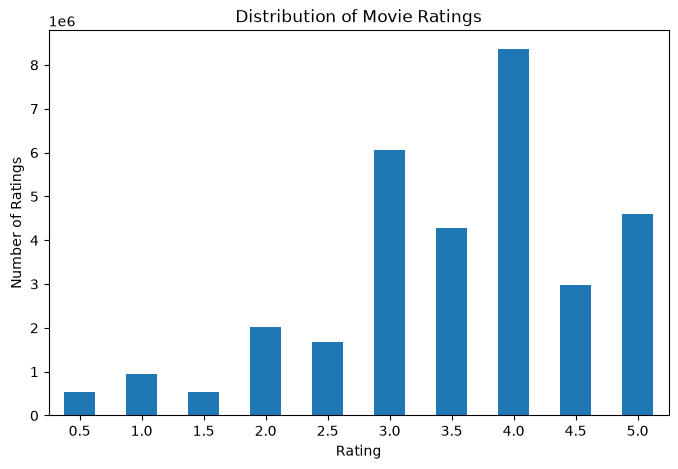

In [78]:
import matplotlib.pyplot as plt

rating_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=0)

plt.show()

In [79]:
positive_rating_count = (ratings["rating"] >= 4).sum()
total_rating_count = len(ratings)

positive_rating_percentage = (
    positive_rating_count / total_rating_count
) * 100

print(f"Positive ratings (>= 4): {positive_rating_count:,}")
print(f"Total ratings: {total_rating_count:,}")
print(f"Positive rating percentage: {positive_rating_percentage:.2f}%")

Positive ratings (>= 4): 15,938,231
Total ratings: 32,000,204
Positive rating percentage: 49.81%


In [80]:
user_rating_counts = ratings.groupby("userId").size()

print("===== RATINGS PER USER =====")
display(user_rating_counts.describe())

===== RATINGS PER USER =====


count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33332.000000
dtype: float64

In [81]:
user_positive_counts = (
    ratings[ratings["rating"] >= 4]
    .groupby("userId")
    .size()
)

print("===== POSITIVE INTERACTIONS PER USER =====")
display(user_positive_counts.describe())

===== POSITIVE INTERACTIONS PER USER =====


count    200726.000000
mean         79.402922
std         113.086445
min           1.000000
25%          21.000000
50%          42.000000
75%          92.000000
max        5525.000000
dtype: float64

In [82]:
print("===== USER ACTIVITY PERCENTILES =====")

display(
    user_positive_counts.quantile(
        [0, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
    )
)

===== USER ACTIVITY PERCENTILES =====


0.00       1.00
0.01       5.00
0.05      10.00
0.10      13.00
0.25      21.00
0.50      42.00
0.75      92.00
0.90     183.00
0.95     268.00
0.99     538.75
1.00    5525.00
dtype: float64

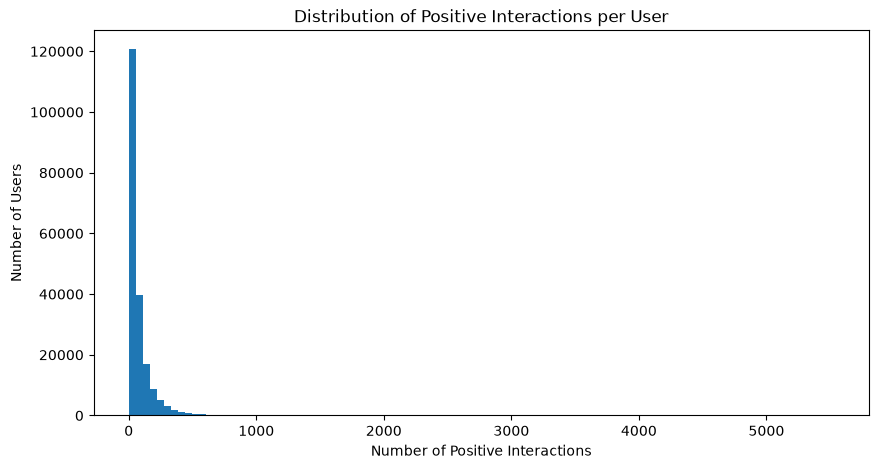

In [83]:
plt.figure(figsize=(10, 5))

user_positive_counts.plot(
    kind="hist",
    bins=100
)

plt.title("Distribution of Positive Interactions per User")
plt.xlabel("Number of Positive Interactions")
plt.ylabel("Number of Users")

plt.show()

In [84]:
movie_rating_counts = ratings.groupby("movieId").size()

print("===== RATINGS PER MOVIE =====")
display(movie_rating_counts.describe())

===== RATINGS PER MOVIE =====


count     84432.000000
mean        379.005638
std        2592.439791
min           1.000000
25%           2.000000
50%           5.000000
75%          25.000000
max      102929.000000
dtype: float64

In [85]:
movie_positive_counts = (
    ratings[ratings["rating"] >= 4]
    .groupby("movieId")
    .size()
)

print("===== POSITIVE INTERACTIONS PER MOVIE =====")
display(movie_positive_counts.describe())

===== POSITIVE INTERACTIONS PER MOVIE =====


count    55174.000000
mean       288.872132
std       2012.036641
min          1.000000
25%          1.000000
50%          3.000000
75%         22.000000
max      88753.000000
dtype: float64

In [86]:
print("===== MOST POPULAR MOVIES =====")

display(
    movie_positive_counts
    .sort_values(ascending=False)
    .head(20)
)

===== MOST POPULAR MOVIES =====


movieId
318     88753
296     77378
356     72552
2571    71950
593     70553
260     63859
2959    61636
527     59310
50      55375
1196    55305
858     54746
4993    54594
1198    50813
7153    50191
5952    49861
2858    48433
110     48031
1210    47813
47      47741
589     47251
dtype: int64

In [87]:
top_movies = (
    movie_positive_counts
    .sort_values(ascending=False)
    .head(20)
    .rename("positive_interactions")
    .reset_index()
)

top_movies = top_movies.merge(
    movies[["movieId", "title", "genres"]],
    on="movieId",
    how="left"
)

display(top_movies)

,movieId,positive_interactions,title,genres
0,318,88753,"Shawshank Redemption, The (1994)",Crime|Drama
1,296,77378,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
2,356,72552,Forrest Gump (1994),Comedy|Drama|Romance|War
3,2571,71950,"Matrix, The (1999)",Action|Sci-Fi|Thriller
4,593,70553,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
5,260,63859,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
6,2959,61636,Fight Club (1999),Action|Crime|Drama|Thriller
7,527,59310,Schindler's List (1993),Drama|War
8,50,55375,"Usual Suspects, The (1995)",Crime|Mystery|Thriller
9,1196,55305,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi


In [88]:
total_positive_interactions = len(
    ratings[ratings["rating"] >= 4]
)

top_10_positive = (
    movie_positive_counts
    .sort_values(ascending=False)
    .head(10)
    .sum()
)

top_100_positive = (
    movie_positive_counts
    .sort_values(ascending=False)
    .head(100)
    .sum()
)

print(
    f"Top 10 movies account for "
    f"{top_10_positive / total_positive_interactions * 100:.2f}% "
    f"of all positive interactions"
)

print(
    f"Top 100 movies account for "
    f"{top_100_positive / total_positive_interactions * 100:.2f}% "
    f"of all positive interactions"
)

Top 10 movies account for 4.25% of all positive interactions
Top 100 movies account for 22.42% of all positive interactions


In [89]:
print("===== GENRE DISTRIBUTION =====")

genre_movie_counts = (
    movies["genres"]
    .str.split("|")
    .explode()
    .value_counts()
)

display(genre_movie_counts)

===== GENRE DISTRIBUTION =====


genres
Drama                 34175
Comedy                23124
Thriller              11823
Romance               10369
Action                 9668
Documentary            9363
Horror                 8654
(no genres listed)     7080
Crime                  6976
Adventure              5402
Sci-Fi                 4907
Animation              4617
Children               4520
Mystery                4013
Fantasy                3851
War                    2325
Western                1696
Musical                1059
Film-Noir               353
IMAX                    195
Name: count, dtype: int64

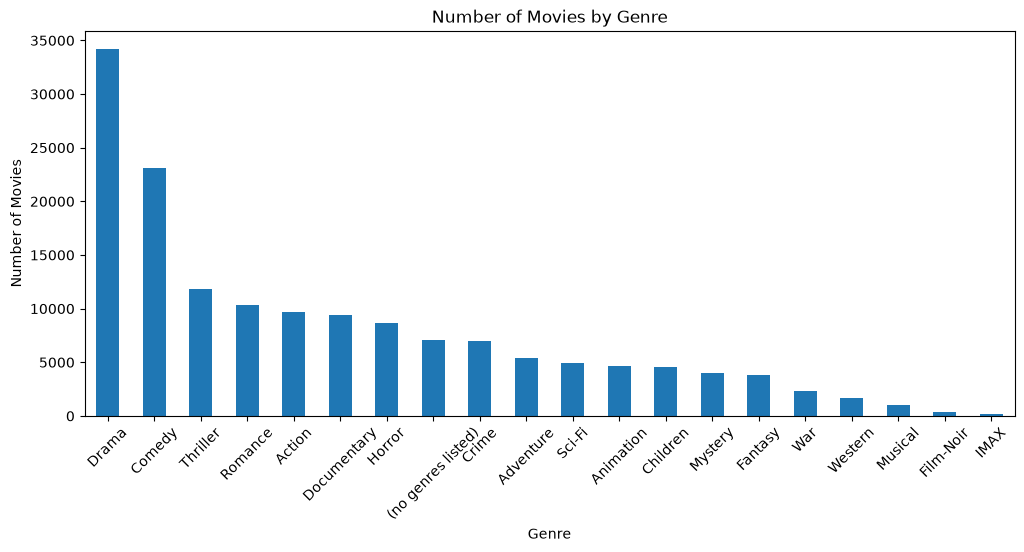

In [90]:
genre_movie_counts.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Number of Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.show()

In [91]:
ratings_with_genres = ratings[
    ["userId", "movieId", "rating", "positive"]
].merge(
    movies[["movieId", "genres"]],
    on="movieId",
    how="left"
)

print("Shape:", ratings_with_genres.shape)

display(ratings_with_genres.head())

Shape: (32000204, 5)


,userId,movieId,rating,positive,genres
0,1,17,4.0,1,Drama|Romance
1,1,25,1.0,0,Drama|Romance
2,1,29,2.0,0,Adventure|Drama|Fantasy|Mystery|Sci-Fi
3,1,30,5.0,1,Crime|Drama
4,1,32,5.0,1,Mystery|Sci-Fi|Thriller


In [92]:
genre_interactions = (
    ratings_with_genres
    .assign(
        genre=ratings_with_genres["genres"].str.split("|")
    )
    .explode("genre")
)

print("Shape after exploding genres:", genre_interactions.shape)

display(
    genre_interactions[
        ["userId", "movieId", "rating", "positive", "genre"]
    ].head(10)
)

Shape after exploding genres: (87119218, 6)


,userId,movieId,rating,positive,genre
0,1,17,4.0,1,Drama
0,1,17,4.0,1,Romance
1,1,25,1.0,0,Drama
1,1,25,1.0,0,Romance
2,1,29,2.0,0,Adventure
2,1,29,2.0,0,Drama
2,1,29,2.0,0,Fantasy
2,1,29,2.0,0,Mystery
2,1,29,2.0,0,Sci-Fi
3,1,30,5.0,1,Crime


In [93]:
genre_rating_stats = (
    genre_interactions
    .groupby("genre")
    .agg(
        ratings=("rating", "size"),
        average_rating=("rating", "mean"),
        positive_interactions=("positive", "sum")
    )
    .sort_values(
        "positive_interactions",
        ascending=False
    )
)

genre_rating_stats

,ratings,average_rating,positive_interactions
genre,,,
Drama,13973271,3.682454,7767984
Comedy,11206926,3.432386,5087919
Action,9665213,3.476407,4514423
Thriller,8679464,3.531702,4242532
Adventure,7590522,3.523439,3704655
Crime,5373051,3.691771,3006682
Romance,5524615,3.545003,2759311
Sci-Fi,5717337,3.491699,2724764
Fantasy,3702759,3.512175,1797234


In [94]:
genre_rating_stats["positive_rate"] = (
    genre_rating_stats["positive_interactions"]
    / genre_rating_stats["ratings"]
    * 100
)

display(
    genre_rating_stats
    .sort_values("positive_rate", ascending=False)
)

,ratings,average_rating,positive_interactions,positive_rate
genre,,,,
Film-Noir,304710,3.915774,203360,66.738866
War,1594110,3.791699,968466,60.752771
Documentary,427353,3.691182,243090,56.882718
Crime,5373051,3.691771,3006682,55.958561
Drama,13973271,3.682454,7767984,55.591737
Mystery,2615322,3.673103,1444991,55.250979
Animation,2214562,3.615332,1162925,52.512641
Western,596654,3.600175,311883,52.272004
IMAX,1494179,3.593312,762104,51.004866


In [95]:
user_genre_stats = (
    genre_interactions
    .groupby(["userId", "genre"])
    .agg(
        interactions=("rating", "size"),
        positive_interactions=("positive", "sum"),
        average_rating=("rating", "mean")
    )
    .reset_index()
)

user_genre_stats.head(20)

,userId,genre,interactions,positive_interactions,average_rating
0,1,Action,19,14,4.105263
1,1,Adventure,17,11,3.470588
2,1,Children,2,1,3.500000
3,1,Comedy,51,28,3.333333
4,1,Crime,16,10,3.875000
5,1,Documentary,1,0,3.000000
6,1,Drama,102,63,3.549020
7,1,Fantasy,8,2,2.500000
8,1,Film-Noir,1,1,5.000000
9,1,Horror,3,1,3.666667


In [96]:
user_genre_stats["positive_rate"] = (
    user_genre_stats["positive_interactions"]
    / user_genre_stats["interactions"]
    * 100
)

display(user_genre_stats.head(20))

,userId,genre,interactions,positive_interactions,average_rating,positive_rate
0,1,Action,19,14,4.105263,73.684211
1,1,Adventure,17,11,3.470588,64.705882
2,1,Children,2,1,3.500000,50.000000
3,1,Comedy,51,28,3.333333,54.901961
4,1,Crime,16,10,3.875000,62.500000
5,1,Documentary,1,0,3.000000,0.000000
6,1,Drama,102,63,3.549020,61.764706
7,1,Fantasy,8,2,2.500000,25.000000
8,1,Film-Noir,1,1,5.000000,100.000000
9,1,Horror,3,1,3.666667,33.333333


In [97]:
sample_user_genres = (
    user_genre_stats[
        user_genre_stats["userId"] == sample_user
    ]
    .sort_values(
        "positive_rate",
        ascending=False
    )
)

display(sample_user_genres)

,userId,genre,interactions,positive_interactions,average_rating,positive_rate
239140,14563,Documentary,2,2,4.500000,100.000000
239151,14563,War,22,21,4.363636,95.454545
239134,14563,Action,98,64,3.811224,65.306122
239141,14563,Drama,106,68,3.924528,64.150943
239139,14563,Crime,37,23,3.959459,62.162162
239152,14563,Western,5,3,4.100000,60.000000
239147,14563,Mystery,12,7,4.041667,58.333333
239149,14563,Sci-Fi,56,31,3.642857,55.357143
239150,14563,Thriller,71,39,3.676056,54.929577
239135,14563,Adventure,77,41,3.590909,53.246753


In [98]:
print("===== TAG DATASET =====")

print("Rows:", tags.shape[0])
print("Columns:", tags.shape[1])

print("\nUnique users:", tags["userId"].nunique())
print("Unique movies:", tags["movieId"].nunique())
print("Unique tags:", tags["tag"].nunique())

display(tags.head(10))

===== TAG DATASET =====
Rows: 2000072
Columns: 4

Unique users: 15848
Unique movies: 51323
Unique tags: 140979


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102
5,34,8623,Steve Martin,1249808497
6,55,5766,the killls and the score,1319322078
7,58,7451,bullying,1672551536
8,58,7451,clique,1672551510
9,58,7451,coming of age,1672551502


In [99]:
print("===== MOST COMMON TAGS =====")

tag_counts = (
    tags["tag"]
    .value_counts()
)

display(tag_counts.head(30))

===== MOST COMMON TAGS =====


tag
sci-fi                10996
atmospheric            9589
action                 8473
comedy                 8139
funny                  7467
surreal                7231
visually appealing     7090
based on a book        6617
twist ending           6521
dark comedy            6053
thought-provoking      6000
dystopia               5646
violence               5389
cinematography         5277
romance                5271
murder                 5180
social commentary      5152
stylized               4917
fantasy                4844
psychology             4827
time travel            4682
quirky                 4650
dark                   4529
classic                4482
adventure              4387
coming of age          4350
friendship             4257
suspense               4227
revenge                4200
BD-R                   3967
Name: count, dtype: int64

In [100]:
tagged_movie_count = tags["movieId"].nunique()
total_movie_count = movies["movieId"].nunique()

print("Movies with tags:", tagged_movie_count)
print("Total movies:", total_movie_count)

print(
    f"Tag coverage: "
    f"{tagged_movie_count / total_movie_count * 100:.2f}%"
)

Movies with tags: 51323
Total movies: 87585
Tag coverage: 58.60%


In [101]:
tags_per_movie = (
    tags.groupby("movieId")
    .size()
)

print("===== TAGS PER MOVIE =====")
display(tags_per_movie.describe())

===== TAGS PER MOVIE =====


count    51323.000000
mean        38.970286
std        160.935483
min          1.000000
25%          2.000000
50%          5.000000
75%         16.000000
max       6697.000000
dtype: float64

In [102]:
print("Tag count percentiles:")

display(
    tags_per_movie.quantile(
        [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.0]
    )
)

Tag count percentiles:


0.00       1.0
0.25       2.0
0.50       5.0
0.75      16.0
0.90      68.0
0.95     171.0
0.99     631.0
1.00    6697.0
dtype: float64

In [103]:
tag_users = set(tags["userId"].unique())
rating_users = set(ratings["userId"].unique())

users_who_rate_and_tag = tag_users & rating_users

print("Users who tag:", len(tag_users))
print("Users who rate:", len(rating_users))
print("Users who do both:", len(users_who_rate_and_tag))

print(
    f"Percentage of taggers who also rate: "
    f"{len(users_who_rate_and_tag) / len(tag_users) * 100:.2f}%"
)

Users who tag: 15848
Users who rate: 200948
Users who do both: 15848
Percentage of taggers who also rate: 100.00%


In [104]:
print("===== TEMPORAL COVERAGE =====")

print("Earliest rating:", ratings["date"].min())
print("Latest rating:", ratings["date"].max())
print("Time span:", ratings["date"].max() - ratings["date"].min())

===== TEMPORAL COVERAGE =====
Earliest rating: 1995-01-09 11:46:44
Latest rating: 2023-10-13 02:29:07
Time span: 10503 days 14:42:23


In [105]:
ratings["year"] = ratings["date"].dt.year

yearly_ratings = (
    ratings["year"]
    .value_counts()
    .sort_index()
)

display(yearly_ratings)

year
1995          4
1996    1571368
1997     685388
1998     301691
1999    1174629
2000    1912322
2001    1160098
2002     849762
2003    1011000
2004    1139068
2005    1752573
2006    1141704
2007    1023813
2008    1117071
2009     890696
2010     860073
2011     729301
2012     695493
2013     563301
2014     518537
2015    1743866
2016    1918739
2017    1827953
2018    1391057
2019    1385467
2020    1688159
2021    1239912
2022     913105
2023     794054
Name: count, dtype: int64

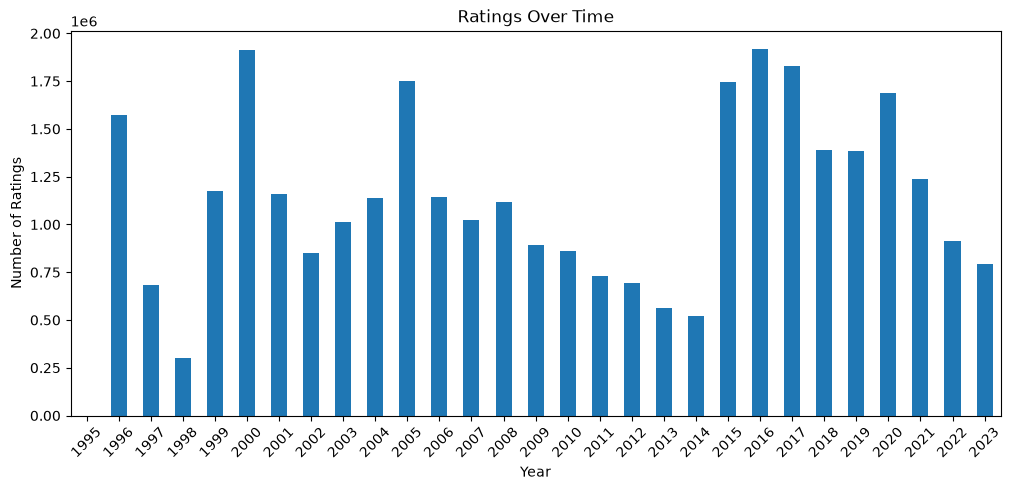

In [106]:
yearly_ratings.plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Ratings Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Ratings")
plt.xticks(rotation=45)

plt.show()

In [107]:
# ============================================
# STAGE 3 — TEMPORAL DATA SPLIT
# Step 1: Inspect timestamps
# ============================================

print("Earliest timestamp:", ratings["timestamp"].min())
print("Latest timestamp:", ratings["timestamp"].max())

print("\nDate range:")
print(ratings["date"].min(), "→", ratings["date"].max())

print("\nColumns:")
print(ratings.columns.tolist())

Earliest timestamp: 789652004
Latest timestamp: 1697164147

Date range:
1995-01-09 11:46:44 → 2023-10-13 02:29:07

Columns:
['userId', 'movieId', 'rating', 'timestamp', 'date', 'positive', 'year']


In [108]:
# ============================================
# STAGE 3 — TEMPORAL DATA SPLIT
# Step 2: Sort interactions chronologically
# ============================================

ratings_sorted = ratings.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Total interactions:", len(ratings_sorted))

print("\nFirst 5 interactions:")
display(
    ratings_sorted[
        ["userId", "movieId", "rating", "timestamp", "date", "positive"]
    ].head()
)

print("\nLast 5 interactions:")
display(
    ratings_sorted[
        ["userId", "movieId", "rating", "timestamp", "date", "positive"]
    ].tail()
)

Total interactions: 32000204

First 5 interactions:


,userId,movieId,rating,timestamp,date,positive
0,25062,1176,4.0,789652004,1995-01-09 11:46:44,1
1,30917,1079,3.0,789652009,1995-01-09 11:46:49,0
2,30917,47,5.0,789652009,1995-01-09 11:46:49,1
3,30917,21,3.0,789652009,1995-01-09 11:46:49,0
4,38835,2,4.0,822873600,1996-01-29 00:00:00,1



Last 5 interactions:


,userId,movieId,rating,timestamp,date,positive
32000199,54315,112818,3.0,1697163923,2023-10-13 02:25:23,0
32000200,54315,197709,3.5,1697163970,2023-10-13 02:26:10,0
32000201,54315,194947,2.5,1697164060,2023-10-13 02:27:40,0
32000202,54315,104457,2.5,1697164098,2023-10-13 02:28:18,0
32000203,54315,116989,2.5,1697164147,2023-10-13 02:29:07,0


In [109]:
# ============================================
# STAGE 3 — TEMPORAL DATA SPLIT
# Step 3: Train / Validation / Test split
# ============================================

n = len(ratings_sorted)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = ratings_sorted.iloc[:train_end].copy()
validation = ratings_sorted.iloc[train_end:val_end].copy()
test = ratings_sorted.iloc[val_end:].copy()

print("===== TEMPORAL SPLIT =====")

print(f"Train:      {len(train):,} interactions")
print(f"Validation: {len(validation):,} interactions")
print(f"Test:       {len(test):,} interactions")

print("\n===== DATE RANGES =====")

print(
    "Train:",
    train["date"].min(),
    "→",
    train["date"].max()
)

print(
    "Validation:",
    validation["date"].min(),
    "→",
    validation["date"].max()
)

print(
    "Test:",
    test["date"].min(),
    "→",
    test["date"].max()
)

===== TEMPORAL SPLIT =====
Train:      22,400,142 interactions
Validation: 4,800,031 interactions
Test:       4,800,031 interactions

===== DATE RANGES =====
Train: 1995-01-09 11:46:44 → 2016-10-13 13:27:26
Validation: 2016-10-13 13:27:36 → 2019-11-09 20:15:03
Test: 2019-11-09 20:15:12 → 2023-10-13 02:29:07


In [110]:
# ============================================
# STAGE 3 — TEMPORAL DATA SPLIT
# Step 4: User / Item overlap analysis
# ============================================

train_users = set(train["userId"].unique())
val_users = set(validation["userId"].unique())
test_users = set(test["userId"].unique())

train_movies = set(train["movieId"].unique())
val_movies = set(validation["movieId"].unique())
test_movies = set(test["movieId"].unique())

print("===== USER OVERLAP =====")

print("Train users:", len(train_users))
print("Validation users:", len(val_users))
print("Test users:", len(test_users))

print("\nValidation users NOT in train:",
      len(val_users - train_users))

print("Test users NOT in train:",
      len(test_users - train_users))

print("\n===== MOVIE OVERLAP =====")

print("Train movies:", len(train_movies))
print("Validation movies:", len(val_movies))
print("Test movies:", len(test_movies))

print("\nValidation movies NOT in train:",
      len(val_movies - train_movies))

print("Test movies NOT in train:",
      len(test_movies - train_movies))

===== USER OVERLAP =====
Train users: 154612
Validation users: 31058
Test users: 30155

Validation users NOT in train: 24007
Test users NOT in train: 26117

===== MOVIE OVERLAP =====
Train movies: 36529
Validation movies: 54692
Test movies: 70541

Validation movies NOT in train: 22710
Test movies NOT in train: 40421


In [111]:
# ============================================
# STAGE 3 — PERSONALIZED TEMPORAL SPLIT
# Step 5: Split each user's history chronologically
# ============================================

# Number of interactions for each user
user_counts = ratings_sorted.groupby("userId")["userId"].transform("size")

# Chronological position of each interaction for that user
user_position = ratings_sorted.groupby("userId").cumcount()

# Convert position into a fraction of the user's history
user_fraction = user_position / user_counts

# 70% earliest interactions → train
# Next 15% → validation
# Final 15% → test

train_personalized = ratings_sorted[
    user_fraction < 0.70
].copy()

validation_personalized = ratings_sorted[
    (user_fraction >= 0.70) &
    (user_fraction < 0.85)
].copy()

test_personalized = ratings_sorted[
    user_fraction >= 0.85
].copy()

# Clean up temporary variables
del user_counts, user_position, user_fraction

print("===== PER-USER TEMPORAL SPLIT =====")

print(f"Train:      {len(train_personalized):,}")
print(f"Validation: {len(validation_personalized):,}")
print(f"Test:       {len(test_personalized):,}")

print("\n===== DATE RANGES =====")

print(
    "Train:",
    train_personalized["date"].min(),
    "→",
    train_personalized["date"].max()
)

print(
    "Validation:",
    validation_personalized["date"].min(),
    "→",
    validation_personalized["date"].max()
)

print(
    "Test:",
    test_personalized["date"].min(),
    "→",
    test_personalized["date"].max()
)

===== PER-USER TEMPORAL SPLIT =====
Train:      22,488,423
Validation: 4,803,475
Test:       4,708,306

===== DATE RANGES =====
Train: 1995-01-09 11:46:44 → 2023-10-13 01:01:00
Validation: 1996-02-01 14:34:24 → 2023-10-13 01:01:18
Test: 1996-02-02 12:37:00 → 2023-10-13 02:29:07


In [112]:
# ============================================
# STAGE 3 — PERSONALIZED TEMPORAL SPLIT
# Step 6: Validate chronological ordering
# ============================================

train_last = (
    train_personalized
    .groupby("userId")["timestamp"]
    .max()
)

validation_first = (
    validation_personalized
    .groupby("userId")["timestamp"]
    .min()
)

validation_last = (
    validation_personalized
    .groupby("userId")["timestamp"]
    .max()
)

test_first = (
    test_personalized
    .groupby("userId")["timestamp"]
    .min()
)

# Check for violations
train_validation_violations = (
    validation_first < train_last
).sum()

validation_test_violations = (
    test_first < validation_last
).sum()

print("===== TEMPORAL ORDERING CHECK =====")

print(
    "Users with Train → Validation ordering violations:",
    train_validation_violations
)

print(
    "Users with Validation → Test ordering violations:",
    validation_test_violations
)

===== TEMPORAL ORDERING CHECK =====
Users with Train → Validation ordering violations: 0
Users with Validation → Test ordering violations: 0


In [113]:
# ============================================
# STAGE 3 — PERSONALIZED TEMPORAL SPLIT
# Step 7: Check user history across splits
# ============================================

train_counts = train_personalized.groupby("userId").size()
val_counts = validation_personalized.groupby("userId").size()
test_counts = test_personalized.groupby("userId").size()

user_split_summary = pd.DataFrame({
    "train_interactions": train_counts,
    "validation_interactions": val_counts,
    "test_interactions": test_counts
}).fillna(0)

print("===== USER HISTORY ACROSS SPLITS =====")

display(user_split_summary.describe())

print("\n===== USERS WITH NO TEST INTERACTIONS =====")
print(
    "Users without test interactions:",
    (user_split_summary["test_interactions"] == 0).sum()
)

print("\n===== USERS WITH TEST INTERACTIONS =====")
print(
    "Users with test interactions:",
    (user_split_summary["test_interactions"] > 0).sum()
)

===== USER HISTORY ACROSS SPLITS =====


,train_interactions,validation_interactions,test_interactions
count,200948.000000,200948.000000,200948.000000
mean,111.911654,23.904070,23.430470
std,197.422906,42.308519,42.296227
min,14.000000,3.000000,3.000000
25%,26.000000,5.000000,5.000000
50%,52.000000,11.000000,10.000000
75%,117.000000,25.000000,25.000000
max,23333.000000,5000.000000,4999.000000



===== USERS WITH NO TEST INTERACTIONS =====
Users without test interactions: 0

===== USERS WITH TEST INTERACTIONS =====
Users with test interactions: 200948


In [114]:
# ============================================
# STAGE 3 — EVALUATION TARGET ANALYSIS
# Step 8: Positive interactions in validation/test
# ============================================

train_positive = train_personalized[train_personalized["positive"] == 1]
validation_positive = validation_personalized[
    validation_personalized["positive"] == 1
]
test_positive = test_personalized[
    test_personalized["positive"] == 1
]

print("===== POSITIVE INTERACTIONS BY SPLIT =====")

print(f"Train positive:      {len(train_positive):,}")
print(f"Validation positive: {len(validation_positive):,}")
print(f"Test positive:       {len(test_positive):,}")

print("\n===== USERS WITH POSITIVE TARGETS =====")

print(
    "Users with validation positives:",
    validation_positive["userId"].nunique()
)

print(
    "Users with test positives:",
    test_positive["userId"].nunique()
)

print("\n===== POSITIVE RATE BY SPLIT =====")

print(
    "Train:",
    round(train_personalized["positive"].mean() * 100, 2),
    "%"
)

print(
    "Validation:",
    round(validation_personalized["positive"].mean() * 100, 2),
    "%"
)

print(
    "Test:",
    round(test_personalized["positive"].mean() * 100, 2),
    "%"
)

===== POSITIVE INTERACTIONS BY SPLIT =====
Train positive:      11,512,202
Validation positive: 2,230,488
Test positive:       2,195,541

===== USERS WITH POSITIVE TARGETS =====
Users with validation positives: 194134
Users with test positives: 193622

===== POSITIVE RATE BY SPLIT =====
Train: 51.19 %
Validation: 46.43 %
Test: 46.63 %


In [115]:
# ============================================
# STAGE 3 — EVALUATION FRAMEWORK
# Step 9: Build test ground truth
# ============================================

# Positive test interactions are the ground truth
test_positive_by_user = (
    test_personalized[
        test_personalized["positive"] == 1
    ]
    .groupby("userId")["movieId"]
    .apply(set)
)

# Movies each user has already seen during training
train_seen_by_user = (
    train_personalized
    .groupby("userId")["movieId"]
    .apply(set)
)

print("===== EVALUATION GROUND TRUTH =====")

print(
    "Users with positive test targets:",
    len(test_positive_by_user)
)

print(
    "Users with training history:",
    len(train_seen_by_user)
)

print(
    "Total positive test interactions:",
    sum(len(x) for x in test_positive_by_user)
)

print("\nExample user:")

example_user = test_positive_by_user.index[0]

print("User ID:", example_user)

print(
    "Training movies:",
    len(train_seen_by_user[example_user])
)

print(
    "Positive test movies:",
    len(test_positive_by_user[example_user])
)

===== EVALUATION GROUND TRUTH =====
Users with positive test targets: 193622
Users with training history: 200948
Total positive test interactions: 2195541

Example user:
User ID: 1
Training movies: 99
Positive test movies: 15


In [116]:
# ============================================
# STAGE 3 — EVALUATION FRAMEWORK
# Step 10: Ranking metrics
# ============================================

import numpy as np


def recall_at_k(recommended, relevant, k):
    """
    Fraction of relevant movies that appear
    in the top-k recommendations.
    """
    
    recommended = recommended[:k]
    
    if len(relevant) == 0:
        return 0.0
    
    hits = len(set(recommended) & set(relevant))
    
    return hits / len(relevant)


def precision_at_k(recommended, relevant, k):
    """
    Fraction of top-k recommendations that are relevant.
    """
    
    recommended = recommended[:k]
    
    if k == 0:
        return 0.0
    
    hits = len(set(recommended) & set(relevant))
    
    return hits / k


def ndcg_at_k(recommended, relevant, k):
    """
    Normalized Discounted Cumulative Gain.
    Gives higher weight to relevant movies appearing
    earlier in the recommendation list.
    """
    
    recommended = recommended[:k]
    relevant = set(relevant)
    
    if len(relevant) == 0:
        return 0.0
    
    dcg = 0.0
    
    for rank, movie_id in enumerate(recommended, start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    
    ideal_hits = min(len(relevant), k)
    
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    
    if idcg == 0:
        return 0.0
    
    return dcg / idcg

In [117]:
# ============================================
# TEST THE METRIC FUNCTIONS
# ============================================

recommended = [10, 20, 30, 40, 50]
relevant = {20, 40, 100}

print("Recommended:", recommended)
print("Relevant:", relevant)

print("\nRecall@5:", recall_at_k(recommended, relevant, 5))
print("Precision@5:", precision_at_k(recommended, relevant, 5))
print("NDCG@5:", ndcg_at_k(recommended, relevant, 5))

Recommended: [10, 20, 30, 40, 50]
Relevant: {40, 100, 20}

Recall@5: 0.6666666666666666
Precision@5: 0.4
NDCG@5: 0.49818925746641285


In [118]:
# Stage 3 — Save Modeling Datasets

In [119]:
# ============================================
# SAVE FINAL MODELING DATASETS
# ============================================

import os

os.makedirs("../data/processed", exist_ok=True)

train_personalized.to_parquet(
    "../data/processed/train_personalized.parquet",
    index=False
)

validation_personalized.to_parquet(
    "../data/processed/validation_personalized.parquet",
    index=False
)

test_personalized.to_parquet(
    "../data/processed/test_personalized.parquet",
    index=False
)

print("Modeling datasets saved successfully!")

print("\nFiles:")
print("✓ train_personalized.parquet")
print("✓ validation_personalized.parquet")
print("✓ test_personalized.parquet")

Modeling datasets saved successfully!

Files:
✓ train_personalized.parquet
✓ validation_personalized.parquet
✓ test_personalized.parquet


In [120]:
import os

for filename in [
    "train_personalized.parquet",
    "validation_personalized.parquet",
    "test_personalized.parquet"
]:
    path = f"../data/processed/{filename}"
    print(filename, "→", os.path.getsize(path) / (1024**2), "MB")

train_personalized.parquet → 249.41498470306396 MB
validation_personalized.parquet → 58.04827880859375 MB
test_personalized.parquet → 58.65437412261963 MB
